# PPML 매출모형: 측정 개선 후보의 제한된 탐색

이 노트북은 **실제자료 preliminary 탐색**이다. 유의성 여부를 본 연구의 확인 결과로 사용하지 않는다. 이미 이전 분석을 본 상태에서 선택한 모형이며, 검정의 추가와 표본 차이를 모두 공개한다. 성공 기준은 20개 예정 결과의 수렴·실패·미추정 및 불확실성을 빠짐없이 남기는 것이다.

매출을 Poisson 카운트 자료라고 가정하지 않는다. 비음수 연속 금액의 조건부 산술평균에 `E[매출|X,FE] = exp(상권 FE + 분기 FE + β ln(1+알려진 예정 시작회차))`라는 평균 명세를 적용하는 Poisson pseudo maximum likelihood(PPML) 후보이다. 조건부 분산이 Poisson과 같다고 가정하지 않고 상권 군집 sandwich 표준오차를 쓴다.

사양은 centroid 500m, 후보 공연 ID 기준 일정 가용률 90%, 총매출·야간매출 공통 관측, 상권×업종 2분기 이상, 결과별 최소 20상권으로 고정한다. 업종 10종 × 총매출/21~24시 매출 2종의 20개 가족에 BH를 적용한다. 결과에 따라 문턱을 바꾸거나 추가 사양을 탐색하지 않는다.

방법 참고(이 노트북은 네트워크 요청을 하지 않음): [Santos Silva·Tenreyro 저자 FAQ](https://personal.lse.ac.uk/tenreyro/lgw.html), [Chen·Roth: 0값이 있는 로그 변환의 단위 문제](https://www.jonathandroth.com/assets/files/LogUniqueHOD0_Draft.pdf).

In [1]:
from pathlib import Path
import os
for name in ['OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'OMP_NUM_THREADS']:
    os.environ[name] = '1'
import json, hashlib, warnings, platform
from datetime import datetime, timezone
import numpy as np
import pandas as pd
from scipy import linalg, stats
from scipy.optimize import linprog
import statsmodels.api as sm
from statsmodels.stats.sandwich_covariance import cov_cluster
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'test/AGENTS.md').exists())
OUT = ROOT/'test/reports'; OUT.mkdir(parents=True, exist_ok=True)
KEY = ['area_id', 'industry_id', 'quarter']
INDUSTRY_IDS = [f'CS100{i:03d}' for i in range(1, 11)]
OUTCOMES = ['total_sales', 'night_sales']
MIN_CLUSTERS = 20; UNIT_WON = 1_000_000; MAXITER = 200
sha = lambda p: hashlib.sha256(p.read_bytes()).hexdigest()
read_json = lambda p: json.loads(p.read_text(encoding='utf-8'))
pd.set_option('display.max_rows', 25)

## 고정 입력 검증

12번 데이터셋 완료 명세와 실험 시작 시 보존한 해시를 확인한다. 본 연구 파일은 읽기만 한다. 미제공 매출은 결측 그대로 두며 점포수로 매출을 나누지 않는다.

In [2]:
plan = read_json(ROOT/'test/metadata/lab_plan.json')
s12_path = ROOT/'reports/final/revised_quarterly/12_dataset_summary.json'
s12 = read_json(s12_path)
assert s12['status']=='complete' and s12['all_inputs_unchanged'] and s12['validation_all_passed']
source_paths = [s12['panel_path'], s12_path.relative_to(ROOT).as_posix(),
                'reports/final/revised_quarterly/13_effects.csv',
                'reports/final/revised_quarterly/13_sample_membership.csv']
input_hashes = {p: sha(ROOT/p) for p in source_paths}
assert input_hashes[s12['panel_path']]==s12['panel_sha256']
assert all(v==plan['protected_sha256'][p] for p,v in input_hashes.items())
panel = pd.read_csv(ROOT/s12['panel_path'], dtype={k:str for k in KEY})
assert len(panel)==18120 and not panel.duplicated(KEY).any()
INDUSTRIES = dict(panel[['industry_id','industry']].drop_duplicates().sort_values('industry_id').values)
assert list(INDUSTRIES)==INDUSTRY_IDS
input_checks = pd.DataFrame([dict(path=p, sha256_before=v, expected_sha256=plan['protected_sha256'][p], passed=True)
                             for p,v in input_hashes.items()])
display(input_checks[['path','passed']])

,path,passed
0,data/analysis/final/revised_quarterly/revised_...,True
1,reports/final/revised_quarterly/12_dataset_sum...,True
2,reports/final/revised_quarterly/13_effects.csv,True
3,reports/final/revised_quarterly/13_sample_memb...,True


해시 일치는 고정 입력을 같은 것으로 읽었다는 뜻이다. 현재 좌표·현재 경계로 과거 분기를 연결한다는 한계는 해소하지 않는다. 알려진 예정회차는 실제 개최·관객·공연 직후 거래량을 측정하지 않는다.

In [3]:
def sample_info(stage, frame):
    return dict(stage=stage, nobs=len(frame), clusters=frame.area_id.nunique(),
                entities=len(frame[['area_id','industry_id']].drop_duplicates()))
def key_hash(frame):
    return hashlib.sha256(frame[KEY].sort_values(KEY).to_csv(index=False, lineterminator='\n').encode('utf-8')).hexdigest()
flow = [sample_info('full_panel', panel)]
observed = panel.total_sales.gt(0) & panel.night_sales.ge(0) & panel[OUTCOMES].notna().all(axis=1)
base = panel.loc[observed].copy(); flow.append(sample_info('common_observed_total_positive_night_nonnegative', base))
base = base.loc[base.availability_pct_centroid500.ge(90)].copy()
flow.append(sample_info('centroid500_availability90', base))
base = base.loc[base.groupby(['area_id','industry_id']).quarter.transform('nunique').ge(2)].copy()
base = base.sort_values(KEY).reset_index(drop=True)
base['x'] = np.log1p(base.known_scheduled_start_count_centroid500)
flow.append(sample_info('at_least_two_quarters', base))
assert len(base)==6791 and base.area_id.nunique()==127 and np.isfinite(base.x).all()
prior_membership = pd.read_csv(ROOT/source_paths[3], dtype={k:str for k in KEY})
prior_centroid90 = prior_membership.loc[prior_membership.scenario.eq('centroid90')]
for outcome, prior in prior_centroid90.groupby('outcome'):
    assert key_hash(base)==key_hash(prior), outcome
print('기존 centroid90 두 결과변수 표본 키 해시 일치')
sample_flow = pd.DataFrame(flow)
display(sample_flow)

기존 centroid90 두 결과변수 표본 키 해시 일치


,stage,nobs,clusters,entities
0,full_panel,18120,151,1510
1,common_observed_total_positive_night_nonnegative,7661,135,693
2,centroid500_availability90,6806,128,665
3,at_least_two_quarters,6791,127,650


공통 결과관측 표본은 기존 수정 분석의 centroid90과 같은 6,791행·127상권이다. 총매출은 양수라는 기존 공통표본 조건을 그대로 따른다. 아래 PPML의 결과별 0전용 그룹 제외 및 업종별 최소 군집 조건 때문에 실제 적합 표본은 달라질 수 있다.

## 분리(separation)와 설계행렬

매출이 모두 0인 상권 또는 분기의 FE는 유한한 최대값 대신 음의 무한대로 향한다. 해당 FE 그룹은 PPML 기울기 추정에 정보를 주지 않으므로 반복 제거하고 제거 키를 기록한다. 야간의 모든 분기가 0인 상권이 제거되면 **관측기간 중 양수 야간매출을 가진 상권에 조건부인 표본**이다. 개별 0행은 양수관측과 함께 있는 한 유지한다. 일반적인 분리는 양수행에서 `X d=0`, 0행에서 `X d≤0`를 만족하며 어느 0행에서 엄격한 음수가 가능한지 선형계획으로 확인한다. 추가 분리가 발견되면 사양을 바꾸지 않고 미추정으로 남긴다.

In [4]:
def remove_zero_groups(frame, outcome):
    d = frame.copy(); removed = []; rounds = 0; area_ids = set(); quarters = set()
    while len(d):
        za = set(d.groupby('area_id')[outcome].sum().loc[lambda s:s.eq(0)].index)
        zq = set(d.groupby('quarter')[outcome].sum().loc[lambda s:s.eq(0)].index)
        mask = d.area_id.isin(za) | d.quarter.isin(zq)
        if not mask.any(): break
        rounds += 1; area_ids.update(za); quarters.update(zq)
        drop = d.loc[mask, KEY].copy()
        drop['outcome'] = outcome; drop['round'] = rounds
        drop['zero_area'] = drop.area_id.isin(za); drop['zero_quarter'] = drop.quarter.isin(zq)
        removed.append(drop); d = d.loc[~mask].copy()
    audit = dict(zero_group_removed_rows=len(frame)-len(d), zero_only_areas=len(area_ids),
                 zero_only_quarters=len(quarters), zero_only_area_ids='|'.join(sorted(area_ids)),
                 zero_only_quarter_ids='|'.join(sorted(quarters)), removal_rounds=rounds)
    removed_df = pd.concat(removed, ignore_index=True) if removed else pd.DataFrame(columns=KEY+['outcome','round','zero_area','zero_quarter'])
    return d.reset_index(drop=True), audit, removed_df

def design_matrix(d):
    D = np.column_stack([pd.get_dummies(d.area_id, dtype=float), pd.get_dummies(d.quarter, dtype=float)])
    _, R, piv = linalg.qr(D, mode='economic', pivoting=True)
    rank = int(np.linalg.matrix_rank(R))
    Z = D[:,piv[:rank]]
    residual_x = d.x.to_numpy()-Z@np.linalg.lstsq(Z,d.x.to_numpy(),rcond=None)[0]
    return np.column_stack([Z, d.x.to_numpy()]), float(np.std(residual_x)), rank

In [5]:
def separation_check(X, y):
    zero = y==0
    if not zero.any(): return dict(separation_status='no_zero_outcomes', separation_objective=0.0)
    result = linprog(X[zero].sum(axis=0), A_ub=X[zero], b_ub=np.zeros(zero.sum()),
                     A_eq=X[~zero], b_eq=np.zeros((~zero).sum()),
                     bounds=[(-1,1)]*X.shape[1], method='highs')
    if not result.success:
        return dict(separation_status='lp_failed', separation_objective=np.nan)
    objective = float(-result.fun)
    return dict(separation_status='remaining_separation' if objective>1e-7 else 'passed',
                separation_objective=objective)

def covariance_and_diagnostics(fit, X, y, groups):
    mu = np.asarray(fit.fittedvalues); n,k = X.shape; g = len(np.unique(groups))
    information = X.T@(mu[:,None]*X)
    score_i = X*(y-mu)[:,None]
    score_g = pd.DataFrame(score_i).groupby(np.asarray(groups)).sum().to_numpy()
    correction = g/(g-1)*(n-1)/(n-k)
    influence = linalg.solve(information, score_g.T, assume_a='pos').T
    covariance = correction*(influence.T@influence)
    covariance = (covariance+covariance.T)/2
    reference = cov_cluster(fit, groups, use_correction=True)
    diag = dict(score_relative_max=float(np.max(np.abs(score_i.sum(axis=0)))/max(1.,np.abs(y).sum())),
                information_rank=int(np.linalg.matrix_rank(information)), information_condition=float(np.linalg.cond(information)),
                covariance_rank=int(np.linalg.matrix_rank(covariance)), covariance_dimension=k,
                covariance_singular=bool(np.linalg.matrix_rank(covariance)<k),
                covariance_min_eigenvalue=float(np.linalg.eigvalsh(covariance).min()),
                covariance_psd_within_tolerance=bool(np.linalg.eigvalsh(covariance).min()>=-1e-8*max(1.,np.diag(covariance).max())),
                slope_variance=float(covariance[-1,-1]), cr1_correction=float(correction),
                covariance_reference_max_abs_error=float(np.max(np.abs(covariance-reference))),
                covariance_reference_match=bool(np.allclose(covariance,reference,rtol=1e-5,atol=1e-8)),
                finite_parameters=bool(np.isfinite(fit.params).all()), finite_covariance=bool(np.isfinite(covariance).all()),
                min_fitted_mean=float(mu.min()), max_fitted_mean=float(mu.max()))
    return covariance, diag

분리 진단의 수치 허용오차는 결과 확인 전에 코드에서 고정한다. 더미의 선형종속은 QR로 제거하고 노출의 FE 내 변화가 없는 경우 추정하지 않는다. 군집 sandwich 전체 공분산은 상권 FE 점수 합이 0에 가깝고 군집 수보다 모수 수가 커서 특이할 수 있다. 이를 노출계수의 분산 실패나 설계행렬의 비식별과 구분한다.

## PPML 적합과 추론

금액은 백만원으로 나누어 적합하되 반올림하지 않는다. `IRLS`, 최대 200회, 허용오차 `1e-10`을 한 번 적용한다. 수렴, 상대 score `1e-8` 이하, 유한한 기울기 분산, 정보행렬 가역성과 reference covariance 일치를 확인한다. 실패하면 p값을 내지 않는다. CR1 보정은 `G/(G-1) × (N-1)/(N-K)`이며 t분포의 자유도는 해당 업종·결과의 `G-1`이다. 이 보정이 20개 안팎 군집에서 정확한 검정 크기를 보장하지는 않는다.

In [6]:
def fit_ppml(d, outcome, unit=UNIT_WON):
    X, within_sd, nuisance_rank = design_matrix(d)
    y = d[outcome].to_numpy()/unit; groups = d.area_id.to_numpy()
    row = dict(nobs=len(d), clusters=d.area_id.nunique(), unit_won=unit,
               residual_x_sd=within_sd, design_columns=X.shape[1], nuisance_rank=nuisance_rank,
               sample_key_sha256=key_hash(d))
    if within_sd<1e-10 or np.linalg.matrix_rank(X)<X.shape[1]:
        return dict(**row,status='no_identifiable_within_change'), None
    row.update(separation_check(X,y))
    if row['separation_status'] not in ['passed','no_zero_outcomes']:
        return dict(**row,status=row['separation_status']), None
    if len(d)<=X.shape[1]: return dict(**row,status='insufficient_residual_df'), None
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model = sm.GLM(y,X,family=sm.families.Poisson())
        fit = model.fit(method='IRLS',maxiter=MAXITER,tol=1e-10)
    row.update(converged=bool(fit.converged), iterations=int(fit.fit_history.get('iteration',-1)),
               warnings=' | '.join(str(w.message) for w in caught))
    covariance, diag = covariance_and_diagnostics(fit,X,y,groups); row.update(diag)
    ok = (row['converged'] and row['score_relative_max']<=1e-8 and row['information_rank']==X.shape[1]
          and row['finite_parameters'] and row['finite_covariance'] and row['slope_variance']>0
          and row['covariance_reference_match'] and row['covariance_psd_within_tolerance'])
    if not ok: return dict(**row,status='numerical_validation_failed'), None
    b=float(fit.params[-1]); se=float(np.sqrt(covariance[-1,-1])); df=row['clusters']-1
    critical=stats.t.ppf(.975,df); low=b-critical*se; high=b+critical*se
    row.update(status='estimated',coefficient=b,standard_error=se,ci_low=low,ci_high=high,
               df_cluster=df,p_value=float(2*stats.t.sf(abs(b/se),df)),
               doubling_pct=float(100*np.expm1(b*np.log(2))),
               doubling_ci_low=float(100*np.expm1(low*np.log(2))),
               doubling_ci_high=float(100*np.expm1(high*np.log(2))))
    return row, dict(fit=fit,X=X,y=y,groups=groups,covariance=covariance)

In [7]:
results=[]; zero_audits=[]; removed_frames=[]; membership=[]; retained={}; fitted={}
for ind in INDUSTRY_IDS:
    initial=base.loc[base.industry_id.eq(ind)].copy()
    for outcome in OUTCOMES:
        d,audit,dropped=remove_zero_groups(initial,outcome)
        audit.update(industry_id=ind,industry=INDUSTRIES[ind],outcome=outcome,
                     initial_rows=len(initial),initial_clusters=initial.area_id.nunique(),
                     retained_rows=len(d),retained_clusters=d.area_id.nunique(),
                     initial_zero_rows=int(initial[outcome].eq(0).sum()),retained_zero_rows=int(d[outcome].eq(0).sum()))
        zero_audits.append(audit); removed_frames.append(dropped); retained[(ind,outcome)]=d
        info=dict(scenario='ppml_centroid90',initial_nobs=len(initial),**audit)
        if d.area_id.nunique()<MIN_CLUSTERS:
            row=dict(nobs=len(d),clusters=d.area_id.nunique(),status='too_few_clusters',sample_key_sha256=key_hash(d)); detail=None
        else:
            try: row,detail=fit_ppml(d,outcome)
            except Exception as error: row=dict(nobs=len(d),clusters=d.area_id.nunique(),status='fit_failed',error=repr(error),sample_key_sha256=key_hash(d)); detail=None
        info.update(row); results.append(info)
        if detail is not None: fitted[(ind,outcome)]=detail
        mem=d[KEY].copy(); mem['outcome']=outcome; mem['status']=row['status']; membership.append(mem)
results=pd.DataFrame(results)
for col in ['coefficient','standard_error','ci_low','ci_high','p_value','doubling_pct','doubling_ci_low','doubling_ci_high']:
    if col not in results: results[col]=np.nan
assert len(results)==20
results['p_bh20']=multipletests(results.p_value.fillna(1).to_numpy(),method='fdr_bh')[1]
results.loc[results.p_value.isna(),'p_bh20']=np.nan
zero_diagnostics=pd.DataFrame(zero_audits)
removed_rows=pd.concat(removed_frames,ignore_index=True)
model_membership=pd.concat(membership,ignore_index=True)
display(results[['industry','outcome','status','nobs','clusters','coefficient','standard_error','p_value','p_bh20']])

,industry,outcome,status,nobs,clusters,coefficient,standard_error,p_value,p_bh20
0,한식음식점,total_sales,estimated,1320,119,0.018154,0.005334,0.000909,0.018182
1,한식음식점,night_sales,estimated,1309,118,0.022399,0.011836,0.060900,0.304499
2,중식음식점,total_sales,estimated,399,42,-0.019871,0.013014,0.134454,0.316632
3,중식음식점,night_sales,estimated,399,42,-0.023980,0.028203,0.400111,0.533482
4,일식음식점,total_sales,estimated,425,41,0.007625,0.014676,0.606209,0.689633
5,일식음식점,night_sales,estimated,413,40,0.050019,0.038296,0.199164,0.331940
6,양식음식점,total_sales,estimated,587,58,-0.032671,0.021370,0.131844,0.316632
7,양식음식점,night_sales,estimated,576,57,-0.075165,0.051607,0.150844,0.316632
8,제과점,total_sales,estimated,466,46,-0.025214,0.024905,0.316758,0.487320
9,제과점,night_sales,estimated,450,43,-0.000588,0.032215,0.985533,0.985533


위 표는 예정한 20개 결과 모두를 포함한다. 미추정은 BH 가족 크기를 줄이지 않도록 내부 계산에서 p=1로 두고 표시값은 결측으로 남긴다. BH는 이 20개 사양 내부 조정이며, 앞선 실험·모형 선택 전체에 대한 오류율을 보장하지 않는다. 유의성은 인과관계의 증거가 아니며 연속 금액의 평균 명세·노출 내생성·공간 의존 문제를 해소하지 않는다.

In [8]:
display(zero_diagnostics[['industry','outcome','initial_zero_rows','zero_only_areas','zero_only_quarters',
                          'zero_group_removed_rows','retained_zero_rows','retained_clusters']])
display(results.reindex(columns=['industry','outcome','status','converged','iterations','score_relative_max',
                                'information_rank','design_columns','covariance_singular','slope_variance',
                                'covariance_reference_match','separation_status']))

,industry,outcome,initial_zero_rows,zero_only_areas,zero_only_quarters,zero_group_removed_rows,retained_zero_rows,retained_clusters
0,한식음식점,total_sales,0,0,0,0,0,119
1,한식음식점,night_sales,38,1,0,11,27,118
2,중식음식점,total_sales,0,0,0,0,0,42
3,중식음식점,night_sales,31,0,0,0,31,42
4,일식음식점,total_sales,0,0,0,0,0,41
5,일식음식점,night_sales,55,1,0,12,43,40
6,양식음식점,total_sales,0,0,0,0,0,58
7,양식음식점,night_sales,49,1,0,11,38,57
8,제과점,total_sales,0,0,0,0,0,46
9,제과점,night_sales,62,3,0,16,46,43


,industry,outcome,status,converged,iterations,score_relative_max,information_rank,design_columns,covariance_singular,slope_variance,covariance_reference_match,separation_status
0,한식음식점,total_sales,estimated,True,9,8.842515e-14,131,131,True,0.000028,True,no_zero_outcomes
1,한식음식점,night_sales,estimated,True,13,9.027408e-14,130,130,True,0.000140,True,passed
2,중식음식점,total_sales,estimated,True,11,3.370252e-14,54,54,True,0.000169,True,no_zero_outcomes
3,중식음식점,night_sales,estimated,True,12,8.209271e-15,54,54,True,0.000795,True,passed
4,일식음식점,total_sales,estimated,True,9,4.269311e-15,53,53,True,0.000215,True,no_zero_outcomes
5,일식음식점,night_sales,estimated,True,13,4.448641e-14,52,52,True,0.001467,True,passed
6,양식음식점,total_sales,estimated,True,10,1.051102e-13,70,70,True,0.000457,True,no_zero_outcomes
7,양식음식점,night_sales,estimated,True,15,7.013858e-14,69,69,True,0.002663,True,passed
8,제과점,total_sales,estimated,True,9,1.033394e-13,58,58,True,0.000620,True,no_zero_outcomes
9,제과점,night_sales,estimated,True,11,2.059594e-13,55,55,True,0.001038,True,passed


제거 기록은 0을 잘못된 자료로 취급했다는 뜻이 아니다. PPML에서 모든 결과가 0인 FE 그룹이 유한 추정값을 갖지 못하는 구조를 드러낸다. 원자료의 0값을 삭제하거나 바꾸지 않으며 해당 키만 실험 적합 표본에서 제외한다. 야간 0값 자체가 실제 무매출인지 공개자료의 관측 방식인지도 이 모형은 판별하지 못한다.

## 매출 단위 불변성 확인

노출 기울기와 robust covariance는 종속변수에 양의 상수를 곱해도 이론상 같아야 한다. 첫 업종(한식) 총매출·야간매출을 백만원과 만원으로 각각 독립 재적합한다. 이는 유의성을 찾는 다른 표본·사양이 아니라 계산 단위 점검이다. 모든 적합에서는 백만원 추정치를 원 단위로 환산한 score와 covariance도 확인한다. 단위검증 실패는 그대로 기록한다.

In [9]:
unit_checks=[]
for (ind,outcome),detail in fitted.items():
    X=detail['X']; y=detail['y']; mu=np.asarray(detail['fit'].fittedvalues); groups=detail['groups']
    yw=y*UNIT_WON; muw=mu*UNIT_WON
    information_won=X.T@(muw[:,None]*X)
    scores=pd.DataFrame(X*(yw-muw)[:,None]).groupby(groups).sum().to_numpy()
    n,k=X.shape; g=len(np.unique(groups)); correction=g/(g-1)*(n-1)/(n-k)
    influence=linalg.solve(information_won,scores.T,assume_a='pos').T
    cov_won=correction*(influence.T@influence)
    err=float(np.max(np.abs(cov_won-detail['covariance'])))
    unit_checks.append(dict(industry_id=ind,outcome=outcome,check='million_to_won_analytic_rescale',
                            coefficient_abs_error=0.0,covariance_max_abs_error=err,
                            passed=bool(np.allclose(cov_won,detail['covariance'],rtol=1e-5,atol=1e-8))))
for outcome in OUTCOMES:
    ind=INDUSTRY_IDS[0]; prior=results.loc[results.industry_id.eq(ind)&results.outcome.eq(outcome)].iloc[0]
    try:
        alternate,_=fit_ppml(retained[(ind,outcome)],outcome,unit=10_000)
        err=abs(alternate.get('coefficient',np.nan)-prior.coefficient)
        se_err=abs(alternate.get('standard_error',np.nan)-prior.standard_error)
        passed=alternate['status']=='estimated' and err<1e-7 and se_err<1e-7
        unit_checks.append(dict(industry_id=ind,outcome=outcome,check='ten_thousand_vs_million_refit',
                                alternate_status=alternate['status'],coefficient_abs_error=err,
                                standard_error_abs_error=se_err,passed=bool(passed)))
    except Exception as error:
        unit_checks.append(dict(industry_id=ind,outcome=outcome,check='ten_thousand_vs_million_refit',passed=False,error=repr(error)))
unit_checks=pd.DataFrame(unit_checks)
display(unit_checks)

,industry_id,outcome,check,coefficient_abs_error,covariance_max_abs_error,passed,alternate_status,standard_error_abs_error
0,CS100001,total_sales,million_to_won_analytic_rescale,0.000000e+00,9.443401e-17,True,NaN,NaN
1,CS100001,night_sales,million_to_won_analytic_rescale,0.000000e+00,3.683165e-14,True,NaN,NaN
2,CS100002,total_sales,million_to_won_analytic_rescale,0.000000e+00,5.637851e-16,True,NaN,NaN
3,CS100002,night_sales,million_to_won_analytic_rescale,0.000000e+00,2.374836e-15,True,NaN,NaN
4,CS100003,total_sales,million_to_won_analytic_rescale,0.000000e+00,1.620232e-15,True,NaN,NaN
5,CS100003,night_sales,million_to_won_analytic_rescale,0.000000e+00,2.414735e-15,True,NaN,NaN
6,CS100004,total_sales,million_to_won_analytic_rescale,0.000000e+00,1.999789e-14,True,NaN,NaN
7,CS100004,night_sales,million_to_won_analytic_rescale,0.000000e+00,1.151856e-14,True,NaN,NaN
8,CS100005,total_sales,million_to_won_analytic_rescale,0.000000e+00,8.187895e-16,True,NaN,NaN
9,CS100005,night_sales,million_to_won_analytic_rescale,0.000000e+00,1.429412e-15,True,NaN,NaN


단위 불변성은 `ln(1+원 매출)`에서 `ln(1+백만원 매출)`로 바꿀 때 변하는 임의적인 +1 단위에 대한 대안을 제공한다. 이것만으로 PPML의 평균 명세가 맞다고 입증하지는 않는다.

## 기존 OLS 비교와 결과 그림

기존 centroid90 OLS는 조건부 로그 평균(기하평균 성격), PPML은 조건부 산술평균을 모형화하므로 계수가 같은 대상을 추정하지 않는다. 기존 OLS의 여러 업종 공동 군집 covariance·자유도와 이번 업종별 군집 계산도 다르다. 양수 야간매출 상권 조건부 표본까지 달라질 수 있으므로 p값의 증감을 성능 우열로 읽지 않는다.

In [10]:
ols=pd.read_csv(ROOT/source_paths[2],dtype={'industry_id':str})
ols=ols.loc[ols.scenario.eq('centroid90')].copy()
ols['outcome']=ols.outcome.map({'log1p_total_sales_won':'total_sales','log1p_night_sales_21_24_won':'night_sales'})
ols=ols[['industry_id','outcome','status','nobs_industry','clusters_industry','coefficient','standard_error','p_value','p_bh20']]
ols=ols.rename(columns={c:'ols_'+c for c in ols if c not in ['industry_id','outcome']})
comparison=results[['industry_id','industry','outcome','status','nobs','clusters','coefficient','standard_error','p_value','p_bh20']].merge(ols,on=['industry_id','outcome'],how='left',validate='one_to_one')
comparison['estimand_note']='PPML conditional arithmetic mean vs OLS conditional log mean; industry-specific vs pooled cluster finite correction'
comparison['same_nobs']=comparison.nobs.eq(comparison.ols_nobs_industry)
display(comparison[['industry','outcome','nobs','ols_nobs_industry','coefficient','ols_coefficient','p_value','ols_p_value']])

,industry,outcome,nobs,ols_nobs_industry,coefficient,ols_coefficient,p_value,ols_p_value
0,한식음식점,total_sales,1320,1320,0.018154,-0.005280,0.000909,0.837939
1,한식음식점,night_sales,1309,1320,0.022399,-0.006590,0.060900,0.926776
2,중식음식점,total_sales,399,399,-0.019871,-0.012038,0.134454,0.446599
3,중식음식점,night_sales,399,399,-0.023980,0.111045,0.400111,0.494707
4,일식음식점,total_sales,425,425,0.007625,-0.013912,0.606209,0.683350
5,일식음식점,night_sales,413,425,0.050019,-0.170522,0.199164,0.335865
6,양식음식점,total_sales,587,587,-0.032671,0.002374,0.131844,0.934108
7,양식음식점,night_sales,576,587,-0.075165,0.173818,0.150844,0.257231
8,제과점,total_sales,466,466,-0.025214,-0.006142,0.316758,0.831818
9,제과점,night_sales,450,466,-0.000588,-0.234097,0.985533,0.253258


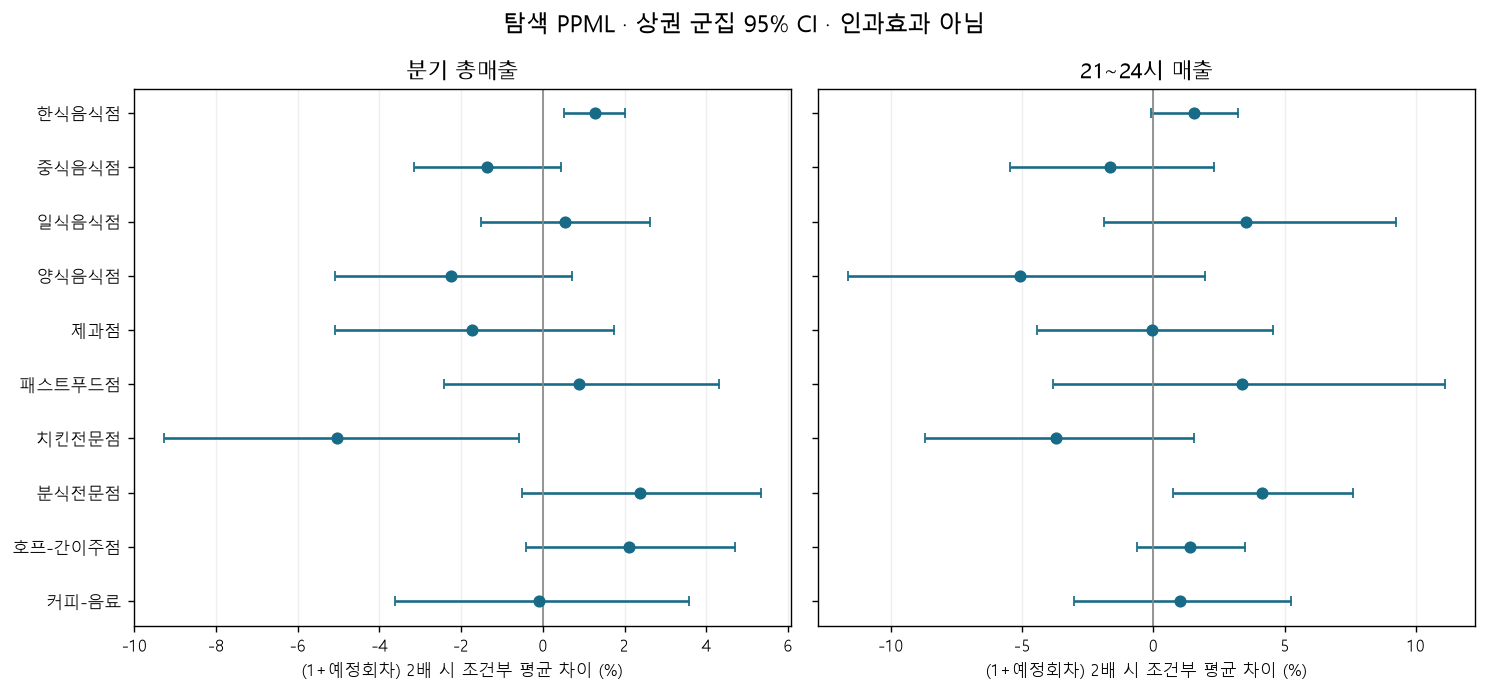

In [11]:
plt.rcParams.update({'font.family':'Malgun Gothic','axes.unicode_minus':False,'figure.dpi':125})
fig,axes=plt.subplots(1,2,figsize=(12,5.6),sharey=True)
for ax,outcome,title in zip(axes,OUTCOMES,['분기 총매출','21~24시 매출']):
    r=results.loc[results.outcome.eq(outcome)].set_index('industry_id').reindex(INDUSTRY_IDS)
    for j,ind in enumerate(INDUSTRY_IDS):
        row=r.loc[ind]
        if row.status=='estimated':
            ax.errorbar(row.doubling_pct,j,xerr=[[row.doubling_pct-row.doubling_ci_low],[row.doubling_ci_high-row.doubling_pct]],fmt='o',color='#176b87',capsize=3)
        else: ax.text(.03,j,'미추정',transform=ax.get_yaxis_transform(),va='center',color='#777777')
    ax.axvline(0,color='#888888',lw=1); ax.set_title(title); ax.set_xlabel('(1+예정회차) 2배 시 조건부 평균 차이 (%)')
    ax.set_yticks(range(10),[INDUSTRIES[i] for i in INDUSTRY_IDS]); ax.grid(axis='x',alpha=.2)
axes[0].invert_yaxis()
fig.suptitle('탐색 PPML · 상권 군집 95% CI · 인과효과 아님',fontsize=13)
fig.tight_layout(); fig.savefig(OUT/'05_coefficient_plot.png',bbox_inches='tight'); plt.show()

그림의 구간은 개별 계수의 95% CI이며 동시 신뢰구간이 아니다. `(1+회차)` 2배에 대한 상대 차이로, 회차 0에서 실제 공연 두 배라는 해석은 할 수 없다. 상권들이 공연 노출을 공유하는 공간 의존은 상권 단위 군집만으로 완전히 처리되지 않는다.

## 저장·무결성 확인 및 해석

20개 전체 결과, 실패, 제거 키, 표본 키, 단위 점검을 `test/reports/05_*`에 저장한다. 이 노트북은 수집을 호출하지 않으며 기존 파일을 변경하지 않는다.

In [12]:
input_checks['sha256_after']=[sha(ROOT/p) for p in input_checks.path]
input_checks['unchanged']=input_checks.sha256_before.eq(input_checks.sha256_after)
assert input_checks.unchanged.all()
for name,frame in {'results':results,'sample_flow':sample_flow,'zero_group_diagnostics':zero_diagnostics,
                   'removed_rows':removed_rows,'sample_membership':model_membership,'unit_checks':unit_checks,
                   'ols_comparison':comparison,'input_checks':input_checks}.items():
    frame.to_csv(OUT/f'05_{name}.csv',index=False,encoding='utf-8-sig')
est=results.loc[results.status.eq('estimated')]
summary=dict(status='complete',section='05',analysis_kind='real_data_exploratory_ppml',confirmatory=False,
             created_utc=datetime.now(timezone.utc).isoformat(),scenario='centroid500_availability90',
             base_rows=len(base),base_areas=base.area_id.nunique(),base_key_sha256=key_hash(base),
             planned_tests=20,estimated_tests=len(est),status_counts=results.status.value_counts().to_dict(),
             raw_p_lt05=int(est.p_value.lt(.05).sum()),bh20_lt05=int(est.p_bh20.lt(.05).sum()),
             minimum_raw_p=None if len(est)==0 else float(est.p_value.min()),
             all_unit_checks_passed=bool(unit_checks.passed.all()),all_inputs_unchanged=bool(input_checks.unchanged.all()),
             removed_rows_across_outcomes=len(removed_rows),
             zero_only_area_industry_pairs=int(zero_diagnostics.zero_only_areas.sum()),
             zero_only_quarters=int(zero_diagnostics.zero_only_quarters.sum()),
             all_converged=bool(est.converged.all()),max_relative_score=float(est.score_relative_max.max()),
             remaining_separation_fits=int(results.status.eq('remaining_separation').sum()),
             minimum_clusters=MIN_CLUSTERS,unit_won=UNIT_WON,
             estimator='Poisson pseudo ML conditional mean log link, separate area and quarter FE by industry',
             inference='area-cluster CR1 with t(G-1); not exact finite-cluster inference',
             family='20 planned industry-outcome tests, missing fits counted as p=1 only for BH computation',
             exploratory_selection_note='chosen after prior results; BH20 does not correct full research search',
             zero_group_scope='night estimates conditional on areas with observed positive night sales if all-zero areas removed',
             source_sha256=input_hashes,network_requests=0,raw_data_mutated=False,
             limitations=s12['limitations']+['PPML mean specification unverified; endogeneity persists',
                'area clustering does not fully address shared spatial exposure','short time dimension; small cluster finite-sample uncertainty',
                'zero-only group handling does not prove night zeros are genuine transactions'],
             software=dict(python=platform.python_version(),numpy=np.__version__,pandas=pd.__version__,statsmodels=sm.__version__))
(OUT/'05_summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
display(pd.DataFrame([dict(planned=20,estimated=len(est),raw_p_lt05=summary['raw_p_lt05'],
                         bh20_lt05=summary['bh20_lt05'],unit_checks_passed=summary['all_unit_checks_passed'],
                         inputs_unchanged=summary['all_inputs_unchanged'])]))

,planned,estimated,raw_p_lt05,bh20_lt05,unit_checks_passed,inputs_unchanged
0,20,20,3,1,True,True


In [13]:
status_text=' · '.join(f'{k}: {v}' for k,v in summary['status_counts'].items())
night_removed=zero_diagnostics.loc[zero_diagnostics.outcome.eq('night_sales'),'zero_group_removed_rows'].sum()
display(Markdown(f"**탐색 결과:** 예정 20개 중 {len(est)}개를 추정했다. {status_text}. "
                 f"통상 p<0.05는 {summary['raw_p_lt05']}개, 이 가족 내부 BH20<0.05는 {summary['bh20_lt05']}개다. "
                 f"야간매출 0전용 FE 그룹에서 {int(night_removed)}행이 제외되었다. "
                 "이 수치는 사후에 선택한 모형의 탐색 기록이며 본 연구의 확인적 유의성이나 인과효과로 사용하지 않는다. "
                 "PPML은 로그 +1의 단위 문제를 피하는 후보이지만, 분기 집계·노출 측정오차·표본 선택 한계는 남는다."))

**탐색 결과:** 예정 20개 중 20개를 추정했다. estimated: 20. 통상 p<0.05는 3개, 이 가족 내부 BH20<0.05는 1개다. 야간매출 0전용 FE 그룹에서 259행이 제외되었다. 이 수치는 사후에 선택한 모형의 탐색 기록이며 본 연구의 확인적 유의성이나 인과효과로 사용하지 않는다. PPML은 로그 +1의 단위 문제를 피하는 후보이지만, 분기 집계·노출 측정오차·표본 선택 한계는 남는다.